# 01 EDA: the competition data

The competition provides 4,407 training knee MRI studies, each a set of DICOM series with a free-text radiology report, and asks for the probability of twelve findings per study. This notebook looks at the parts of the data that shaped the pipeline: how few studies carry radiologist labels, what the reports look like, which series a study has and how the scans differ in geometry.

It reads the competition tables and a table of DICOM header fields saved by the rsna-geom kernel. It shows no images and no report text. It runs on CPU in about a minute.

Paths, finding names and the competition tables: one row per study with its report and, for a few studies, the radiologist labels; one row per series with its plane and contrast flags.

In [1]:
import glob, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

R = next((p for p in ("/kaggle/input/competitions/rsna-knee-abnormality-detection", "/kaggle/input/rsna-knee-abnormality-detection")
          if os.path.exists(f"{p}/train.csv")), "/kaggle/input/competitions/rsna-knee-abnormality-detection")
GEOM = (glob.glob("/kaggle/input/*/geom.csv") + glob.glob("/kaggle/input/notebooks/**/geom.csv", recursive=True))[0]
LAB = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA", "PF OA",
       "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
tr = pd.read_csv(f"{R}/train.csv", encoding_errors="replace")
trs = pd.read_csv(f"{R}/train_series.csv")
gold = tr[tr[LAB[0]].notna()]
print(f"{len(tr)} training studies, {len(trs)} series, {len(gold)} studies with radiologist labels")

4407 training studies, 24371 series, 58 studies with radiologist labels


**Conclusion.** 4,407 training studies with 24,371 series. Only 58 studies carry radiologist labels for the twelve findings; every other study has only its report.

Prevalence of each finding among the 58 labelled studies, the number of positive findings per study, and which findings occur together.

                  positive  share
Effusion                35   0.60
Synovitis               27   0.47
Medial Meniscus         26   0.45
ACL                     24   0.41
Lateral Meniscus        23   0.40
PF OA                   21   0.36
Contusion               19   0.33
Fracture                18   0.31
Medial OA               15   0.26
Baker's                 12   0.21
Lateral OA              11   0.19
MCL                      9   0.16

positive findings per gold study: {'mean': 4.1, 'min': 1.0, '50%': 4.0, 'max': 9.0}
strongest pairwise correlations (phi):
  Medial OA / Baker's: +0.48
  Medial Meniscus / Medial OA: +0.42
  Lateral Meniscus / Lateral OA: +0.42
  Lateral Meniscus / Medial OA: +0.41
  Lateral OA / Baker's: +0.40
  Effusion / Synovitis: +0.40


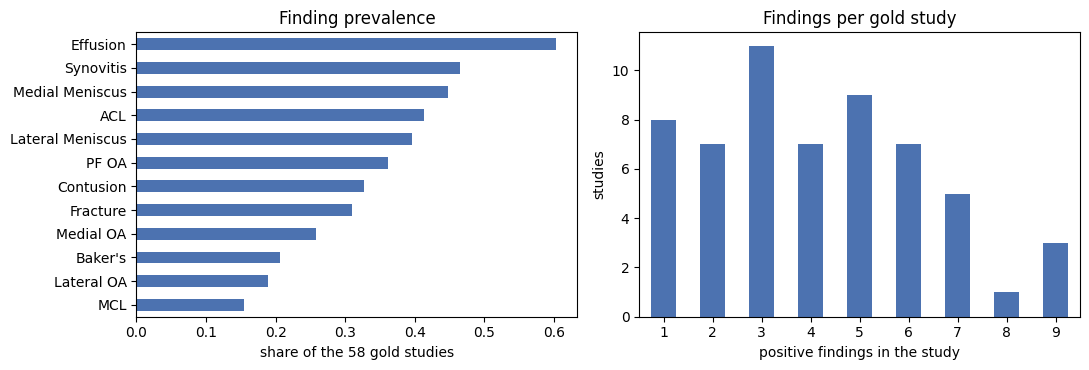

In [2]:
Y = gold[LAB].astype(int)
prev = Y.mean().sort_values()
print(pd.DataFrame({"positive": Y.sum(), "share": Y.mean().round(2)}).loc[prev.index[::-1]].to_string())
k = Y.sum(1)
print("\npositive findings per gold study:", k.describe()[["mean", "min", "50%", "max"]].round(1).to_dict())
C = Y.corr()
pairs = sorted(((a, b, C.loc[a, b]) for i, a in enumerate(LAB) for b in LAB[i + 1:]), key=lambda x: -abs(x[2]))
print("strongest pairwise correlations (phi):")
for a, b, c in pairs[:6]:
    print(f"  {a} / {b}: {c:+.2f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
prev.plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set_xlabel("share of the 58 gold studies")
ax[0].set_title("Finding prevalence")
k.value_counts().sort_index().plot.bar(ax=ax[1], color="#4C72B0", rot=0)
ax[1].set_xlabel("positive findings in the study")
ax[1].set_ylabel("studies")
ax[1].set_title("Findings per gold study")
plt.tight_layout()
plt.show()

**Conclusion.** Findings are common: effusion is present in 60% of the labelled studies and even the rarest, MCL tear, in 16%. A study has 4.1 positive findings on average (1 to 9). Findings cluster: medial OA goes with Baker's cyst (phi 0.48) and with medial meniscal tear (0.42), lateral meniscal tear with lateral OA (0.42), effusion with synovitis (0.40). With 9 to 35 positives per finding, the AUC of one finding on 58 studies has a standard error of several points, so these studies are a noisy ruler for comparing models.

The reports: length and language. The language is guessed from common function words, or from the alphabet for Greek and Cyrillic. It is a rough guess, good enough to see the mix.

report length in characters: {'mean': 1098.0, '5%': 205.0, '50%': 977.0, '95%': 2453.0, 'max': 4743.0}

report language, guessed from common function words:
Report
English            0.394
Spanish            0.158
Turkish            0.124
Croatian           0.092
Greek              0.073
German             0.059
Cyrillic script    0.050
Dutch              0.034
French             0.016
unclear            0.001

gold studies by guessed language: {'English': 28, 'Spanish': 10, 'Turkish': 6, 'Croatian': 4, 'Cyrillic script': 3, 'Greek': 3, 'Dutch': 2, 'German': 2}


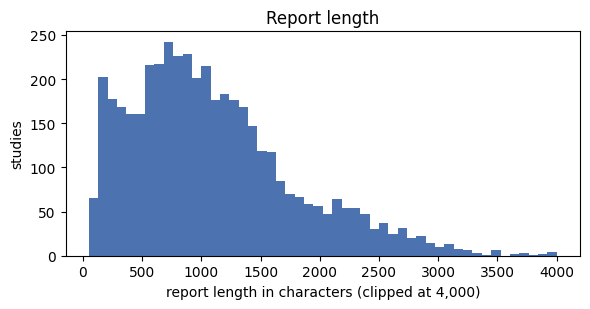

In [3]:
L = tr.Report.fillna("").str.len()
print("report length in characters:", L.describe([.05, .5, .95]).round()[["mean", "5%", "50%", "95%", "max"]].to_dict())
WORDS = {"English": "the and with of there is are no",
         "Spanish": "el los las del con sin y se de la",
         "Portuguese": "do da dos das com sem em ao",
         "German": "der die das und mit nicht kein keine",
         "Dutch": "het een van met geen niet en op",
         "French": "le les des avec et du pas sur",
         "Italian": "il della delle degli di con non lo",
         "Turkish": "ve ile bir izlendi mevcut olarak saptanmadi",
         "Croatian": "je se na su bez od kroz koljena koljeno"}
WORDS = {k: set(v.split()) for k, v in WORDS.items()}


def language(text):
    if sum("\u0370" <= ch <= "\u03ff" for ch in text) > 20:
        return "Greek"
    if sum("\u0400" <= ch <= "\u04ff" for ch in text) > 20:
        return "Cyrillic script"
    toks = text.lower().replace(",", " ").replace(".", " ").replace(":", " ").split()
    hits = {k: sum(t in v for t in toks) for k, v in WORDS.items()}
    best = max(hits, key=hits.get)
    return best if hits[best] >= 2 else "unclear"


lang = tr.Report.fillna("").map(language)
print("\nreport language, guessed from common function words:")
print(lang.value_counts(normalize=True).round(3).to_string())
print("\ngold studies by guessed language:", lang[gold.index].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(L.clip(upper=4000), bins=50, color="#4C72B0")
ax.set_xlabel("report length in characters (clipped at 4,000)")
ax.set_ylabel("studies")
ax.set_title("Report length")
plt.tight_layout()
plt.show()

**Conclusion.** Reports are short (median 977 characters) and written in many languages: about 39% English, 16% Spanish, 12% Turkish, 9% Croatian, 7% Greek, 6% German, 5% Cyrillic script, 3% Dutch and 2% French. Keyword rules would need a vocabulary per language, which is why the training labels come from a multilingual language model (stage 03). The 58 labelled studies cover eight of these languages, with English the largest group (28 studies).

The series: how many per study, which planes, and how often a study has each kind of series that the volume builder (stage 02) looks for.

In [4]:
per = trs.groupby("StudyInstanceUID").size()
print("series per study:", per.describe()[["mean", "min", "50%", "max"]].round(1).to_dict())
print("fluid-sensitive and fat-suppressed flags agree on every series:", bool((trs.Fluid_Sensitive == trs.Fat_Suppression).all()))
print("\nseries by plane:")
print(pd.crosstab(trs.Anatomical_Plane, trs.Fluid_Sensitive.map({0: "not fluid-sensitive", 1: "fluid-sensitive"})).to_string())
SLOTS = [("Sagittal", 1), ("Sagittal", 0), ("Coronal", 1), ("Coronal", 0), ("Axial", 1)]
print("\nshare of studies with at least one series of each kind:")
for plane, fluid in SLOTS:
    s = trs[(trs.Anatomical_Plane == plane) & (trs.Fluid_Sensitive == fluid)].StudyInstanceUID.nunique() / len(per)
    print(f"  {plane:9s} {'fluid-sensitive' if fluid else 'not fluid-sensitive':20s} {s:.3f}")

series per study: {'mean': 5.5, 'min': 3.0, '50%': 5.0, 'max': 14.0}
fluid-sensitive and fat-suppressed flags agree on every series: True

series by plane:
Fluid_Sensitive   fluid-sensitive  not fluid-sensitive
Anatomical_Plane                                      
Axial                        4719                 1179
Coronal                      4624                 3985
Sagittal                     4667                 5197

share of studies with at least one series of each kind:
  Sagittal  fluid-sensitive      0.942
  Sagittal  not fluid-sensitive  0.968
  Coronal   fluid-sensitive      0.964
  Coronal   not fluid-sensitive  0.773
  Axial     fluid-sensitive      1.000


**Conclusion.** A study has 3 to 14 series, 5 at the median. The fluid-sensitive and fat-suppressed flags agree on every series, so they carry one bit of information between them. Every study has an axial fluid-sensitive series; a sagittal or coronal fluid-sensitive series is missing from 6% and 4% of studies, and a coronal series that is not fluid-sensitive (the coronal T1 slot) from 23%. The volume builder therefore falls back to any series of the plane for the fluid-sensitive slots and leaves a T1 slot empty when there is none.

DICOM header fields per series, saved by the rsna-geom kernel: scanner vendor, laterality tag, number of slices, slice thickness, pixel spacing and field of view.

                    studies  share  laterality tag
vendor                                            
Canon (Toshiba)         226  0.051            0.00
Fujifilm (Hitachi)       24  0.005            1.00
GE                      905  0.205            0.04
Philips                1301  0.295            0.38
Siemens                1951  0.443            0.84

studies with a laterality tag: 0.500

per series, median (5th to 95th percentile):
                          slices   slice thickness mm     pixel spacing mm  field of view mm
Anatomical_Plane                                                                            
Axial             32 (19 to 144)  3.00 (0.60 to 4.00)  0.31 (0.16 to 0.56)  160 (140 to 180)
Coronal            30 (16 to 38)  3.00 (3.00 to 4.00)  0.31 (0.17 to 0.56)  160 (140 to 180)
Sagittal           30 (19 to 51)  3.00 (2.00 to 4.00)  0.33 (0.17 to 0.62)  160 (148 to 190)


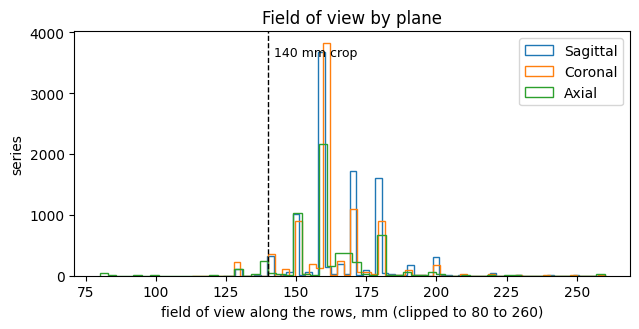

In [5]:
g = pd.read_csv(GEOM, usecols=["StudyInstanceUID", "Anatomical_Plane", "n", "rows", "cols", "ps0", "ps1", "thick", "man", "lat"])
VENDOR = {"PHIL": "Philips", "SIEM": "Siemens", "GE M": "GE", "GEHC": "GE", "TOSH": "Canon (Toshiba)", "CANO": "Canon (Toshiba)",
          "FUJI": "Fujifilm (Hitachi)", "HITA": "Fujifilm (Hitachi)"}
g["vendor"] = g.man.fillna("").str.upper().str[:4].map(VENDOR).fillna("other")
g["tag"] = g.lat.fillna("").astype(str).str.upper().isin(["L", "R", "LEFT", "RIGHT"])
g["fov"] = g.rows * g.ps0
g["thick"] = pd.to_numeric(g.thick, errors="coerce")
st = g.groupby("StudyInstanceUID").agg(vendor=("vendor", "first"), tag=("tag", "any"))
print(pd.DataFrame({"studies": st.vendor.value_counts(), "share": st.vendor.value_counts(normalize=True).round(3),
                    "laterality tag": st.groupby("vendor").tag.mean().round(2)}).to_string())
print(f"\nstudies with a laterality tag: {st.tag.mean():.3f}")
q = lambda s: f"{s.median():.0f} ({s.quantile(.05):.0f} to {s.quantile(.95):.0f})"
q1 = lambda s: f"{s.median():.2f} ({s.quantile(.05):.2f} to {s.quantile(.95):.2f})"
print("\nper series, median (5th to 95th percentile):")
print(pd.DataFrame({"slices": g.groupby("Anatomical_Plane").n.apply(q),
                    "slice thickness mm": g.groupby("Anatomical_Plane").thick.apply(q1),
                    "pixel spacing mm": g.groupby("Anatomical_Plane").ps0.apply(q1),
                    "field of view mm": g.groupby("Anatomical_Plane").fov.apply(q)}).to_string())
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for plane in ["Sagittal", "Coronal", "Axial"]:
    ax.hist(g.fov[g.Anatomical_Plane == plane].clip(80, 260), bins=60, histtype="step", lw=1.5, label=plane)
ax.axvline(140, color="k", ls="--", lw=1)
ax.text(142, ax.get_ylim()[1] * 0.9, "140 mm crop", fontsize=9)
ax.set_xlabel("field of view along the rows, mm (clipped to 80 to 260)")
ax.set_ylabel("series")
ax.set_title("Field of view by plane")
ax.legend()
plt.tight_layout()
plt.show()

**Conclusion.** Five vendors, led by Siemens (44% of studies), Philips (30%) and GE (21%). The DICOM laterality tag is present in exactly half of the studies, mostly from Siemens (84% of its studies) and Philips (38%); GE (4%) and Canon (0%) studies almost never carry it, so the side of the knee has to be inferred for them (stage 04). A typical series has 30 slices of 3 mm with 0.3 mm pixels. The field of view is 160 mm at the median and at least 140 mm in about 95% of series, so a 140 mm crop around the centre keeps the joint, rarely needs padding and puts every study on one physical scale.

The test set as this run sees it. A normal run mounts only a few example test studies; the hidden test set, about 1,300 studies, is mounted only when a submission is scored.

In [6]:
te = pd.read_csv(f"{R}/test_series.csv")
sub = pd.read_csv(f"{R}/sample_submission.csv")
print(f"{len(sub)} test studies and {len(te)} series visible in this run")
print("submission columns:", list(sub.columns))

3 test studies and 15 series visible in this run
submission columns: ['StudyInstanceUID', 'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


**Conclusion.** 3 example test studies with 15 series are visible here. The submission needs one row per study with a probability for each of the twelve findings.